<a href="https://colab.research.google.com/github/RTWh7a/Boston-House-Price-Predictions/blob/main/Competation_1_GCI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Strategic Academic Framework: Default Risk Prediction Pipeline

This document provides an academic overview of the machine learning pipeline developed to assess and predict customer loan default risks. The architecture is split into four deliberate phases: Domain-specific Data Preparation, Leakage-free Preprocessing, Multi-family Model Benchmarking, and Ensemble Optimization.

---

## 1. Feature Engineering & Domain Economics
Financial credit datasets are highly complex and non-linear. Standard statistical summaries often miss interactions between absolute financial values. To address this, we construct explicit economic ratios:
- **Debt-to-Income Ratio (Annuity / Income):** Quantifies monthly debt service burden against total income.
- **Credit-to-Income Ratio (Credit / Income):** Measures overall leverage and total outstanding principal scale against base income.
- **Goods-to-Credit Ratio (Goods Price / Credit):** Captures the loan-to-value (LTV) metric, showing how much of the loan represents actual collateral values vs. unsecured cash.
- **Annuity-to-Credit Ratio:** Acts as a proxy for the loan's duration, interest rates, and structural repayment schedule.

---

## 2. Leakage Prevention & Class Imbalance Strategy
Class imbalance (where default instances represent only ~8% of total observations) introduces significant model bias. Traditional balance techniques, such as **SMOTE**, synthesize minority records. However, doing so introduces severe data leakage if validation sets are transformed.

We utilize a more rigorous framework:
- **No-leakage Scaling:** The `StandardScaler` calculates mean ($\

# About In-Class Competition

## The in-class competition is modified version of the “Home Credit Default Risk” competition originally held on Kaggle.

## Your task is to **build a model to predict the probability of customer loandefault based on the provided customer data.**

```markdown
## Step 1: Import Libraries & Configure Environment
We start by importing crucial data science and scientific computing libraries. In this stage, we also disable warnings to keep our console output clean and readable.
```

### Import libraries and data loading

1.   Import libraries
2.   Load data from drive



In [ ]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Connect drive file
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/Competition"

/content/drive/MyDrive/Competition


In [ ]:
#Read files
import os
from pathlib import Path

#Define path
current_dir = Path(os.getcwd())

train_file = current_dir /'input' /'train.csv'
test_file = current_dir / 'input' /'test.csv'
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


### Secound load data


1.   Data deeply understanding
2.   Preprocessing the data



```markdown
## Step 2: Exploratory Data Analysis & Preprocessing
Understanding the data structure is key to effective modeling. In this section, we load the raw datasets, analyze features, handle missing values (like replacing null values in `OWN_CAR_AGE` with `0` and imputing `EXT_SOURCE_2` with its mean), and explore features with visualizations.
```

In [ ]:
#Load data
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
df_train = train.copy()
df_test = test.copy()

In [ ]:
#Train shape and head
print(f"Train shape: {train.shape}")
train.head()

Train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [ ]:
#Test shape and head
print(f"Test shape: {test.shape}")
test.head()

Test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


In [ ]:
#Info about train
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  object 
 2   CODE_GENDER                 171202 non-null  object 
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  object 
 9   NAME_EDUCATION_TYPE         171202 non-null  object 
 10  NAME_FAMILY_STATUS          171202 non-null  object 
 11  NAME_HOUSING_TYPE           171202 non-null  object 
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH    

We don't need all feautures so we need select most important features

In [ ]:
#Feature selection
# Focus on 5 features
use_features = [
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_2",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    "CNT_CHILDREN",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH"
]
target = df_train["TARGET"]

# Select features from df_train and df_test instead of train and test to avoid KeyError
train = df_train[use_features + ["TARGET"]]
test = df_test[use_features]

In [ ]:
#Shape of train data
print(f"Train shape: {train.shape}")
train.head()

Train shape: (171202, 18)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,TARGET
0,Cash loans,112500.0,0.372591,NaN,School,0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,-9233,-878,-333.0,-522,0
1,Cash loans,225000.0,0.449567,NaN,XNA,0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-20148,365243,-4469.0,-3436,0
2,Cash loans,54000.0,0.569503,NaN,Postal,0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,-18496,-523,-3640.0,-2050,0
3,Cash loans,67500.0,0.105235,NaN,XNA,0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,-24177,365243,-4950.0,-3951,0
4,Cash loans,157500.0,0.202490,NaN,Business Entity Type 3,0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,-10685,-697,-5101.0,-3226,1


In [ ]:
#Test data
print(f"Test shape: {test.shape}")
test.head()

Test shape: (61500, 17)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH
0,Cash loans,144000.0,0.720416,NaN,Kindergarten,1,961146.0,28233.0,688500.0,Working,Higher education,Married,House / apartment,-12108,-2372,-2446.0,-3022
1,Cash loans,103500.0,0.287306,NaN,School,0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,Married,House / apartment,-17907,-1712,-10450.0,-253
2,Cash loans,180000.0,0.352456,NaN,Trade: type 7,1,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-15221,-553,-1056.0,-4495
3,Revolving loans,225000.0,0.470384,NaN,Business Entity Type 3,2,450000.0,22500.0,450000.0,Working,Higher education,Married,House / apartment,-11217,-1438,-6096.0,-1189
4,Cash loans,144000.0,0.373133,14.0,Business Entity Type 3,2,545040.0,26640.0,450000.0,Working,Higher education,Married,House / apartment,-11415,-2362,-3257.0,-1728


In [ ]:
#Preprocession data
train.isna().sum()


,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,369
OWN_CAR_AGE,112992
ORGANIZATION_TYPE,0
CNT_CHILDREN,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0


In [ ]:
test.isna().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,130
OWN_CAR_AGE,40909
ORGANIZATION_TYPE,0
CNT_CHILDREN,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0


In [ ]:
train["OWN_CAR_AGE"].unique()

array([nan,  1.,  6., 20., 15., 64.,  8.,  2.,  5.,  9., 29., 10., 11.,
        0., 21.,  3., 16., 13., 12., 65.,  4.,  7., 18., 27., 14., 26.,
       22., 19., 17., 23., 36., 25., 33., 37., 28., 24., 31., 34., 43.,
       30., 38., 32., 40., 41., 39., 35., 42., 45., 54., 49., 46., 57.,
       44., 55., 91.])

In [ ]:
train["OWN_CAR_AGE"].fillna(0, inplace=True)
test["OWN_CAR_AGE"].fillna(0, inplace=True)

In [ ]:
train['EXT_SOURCE_2']=train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean())
test["EXT_SOURCE_2"]=test["EXT_SOURCE_2"].fillna(test["EXT_SOURCE_2"].mean())

### 2.3. Handling Missing and Unknown Values
To ensure our downstream algorithms run smoothly without numerical errors, we impute features containing missing values:
- **`OWN_CAR_AGE`**: Missing values are filled with `0` under the assumption that a missing value indicates the applicant does not own a car.
- **`EXT_SOURCE_2`**: Since this is a highly predictive score, we replace missing values with the column's mean value to preserve the feature's distribution without removing valuable records.

In [ ]:
train.isna().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,0
OWN_CAR_AGE,0
ORGANIZATION_TYPE,0
CNT_CHILDREN,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0


In [ ]:
train["EXT_SOURCE_2"].unique()

array([0.37259065, 0.44956692, 0.56950335, ..., 0.74024572, 0.72812733,
       0.07214539])

In [ ]:
#Statistical summary
train.describe()

,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,TARGET
count,1.712020e+05,1.712020e+05,171202.000000,171202.000000,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,171202.000000
mean,1.683712e+05,5.145083e-01,4.088399,0.416490,5.991293e+05,27120.065953,5.380569e+05,-16045.340504,63960.411969,-4994.982524,-2990.486005,0.080729
std,1.072348e+05,1.910667e-01,8.975159,0.720138,4.028170e+05,14450.252689,3.685727e+05,4363.792228,141401.513149,3525.760241,1509.694163,0.272420
min,2.610000e+04,8.173617e-08,0.000000,0.000000,4.500000e+04,1980.000000,4.500000e+04,-25229.000000,-17912.000000,-24672.000000,-7197.000000,0.000000
25%,1.125000e+05,3.926621e-01,0.000000,0.000000,2.700000e+05,16546.500000,2.385000e+05,-19686.000000,-2772.000000,-7490.000000,-4297.000000,0.000000
50%,1.462500e+05,5.657976e-01,0.000000,0.000000,5.146020e+05,24916.500000,4.500000e+05,-15778.000000,-1215.000000,-4515.000000,-3247.000000,0.000000
75%,2.025000e+05,6.639672e-01,5.000000,1.000000,8.086500e+05,34600.500000,6.795000e+05,-12420.000000,-288.000000,-2008.000000,-1714.250000,0.000000
max,1.350000e+07,8.549997e-01,91.000000,14.000000,4.050000e+06,170986.500000,2.254500e+06,-7673.000000,365243.000000,0.000000,0.000000,1.000000


In [ ]:
grop_plot = train.groupby("ORGANIZATION_TYPE")['AMT_INCOME_TOTAL'].agg(['mean', 'sum','count'])
grop_plot

,mean,sum,count
ORGANIZATION_TYPE,,,
Advertising,214981.481481,5.224050e+07,243
Agriculture,143237.219731,1.916514e+08,1338
Bank,200544.235018,2.777538e+08,1385
Business Entity Type 1,185254.486905,6.154154e+08,3322
Business Entity Type 2,170307.697154,1.008732e+09,5923
Business Entity Type 3,188199.063930,7.140837e+09,37943
Cleaning,153570.205479,2.242125e+07,146
Construction,198853.839730,7.357592e+08,3700
Culture,176557.389163,3.584115e+07,203


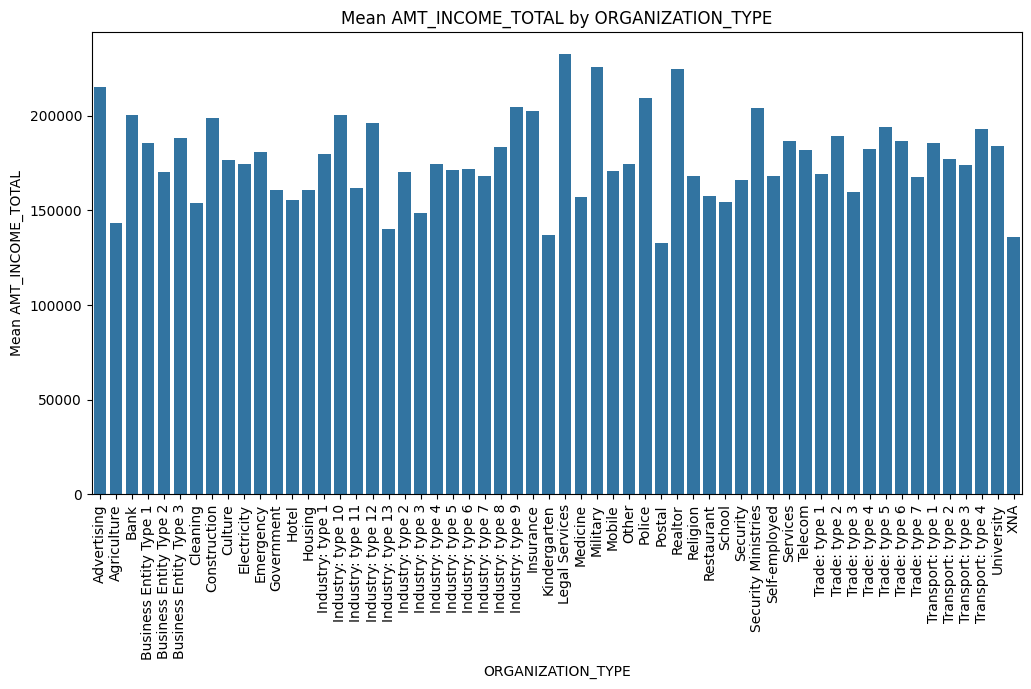

In [ ]:
#Plot the data
plt.figure(figsize=(12, 6))
sns.barplot(x=grop_plot.index, y=grop_plot['mean'], data=grop_plot)
plt.xticks(rotation=90)
plt.xlabel('ORGANIZATION_TYPE')
plt.ylabel('Mean AMT_INCOME_TOTAL')
plt.title('Mean AMT_INCOME_TOTAL by ORGANIZATION_TYPE')
plt.show()

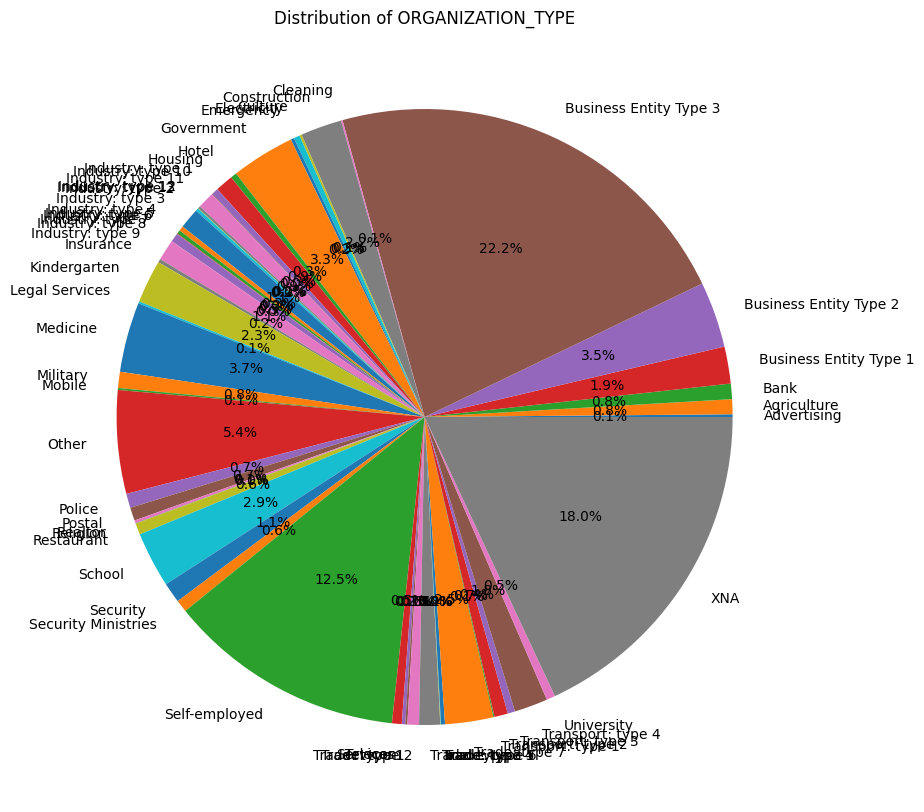

In [ ]:
#Pie plot
plt.figure(figsize=(30, 10))
plt.pie(grop_plot['count'], labels=grop_plot.index, autopct='%1.1f%%')
plt.title('Distribution of ORGANIZATION_TYPE')
plt.show()

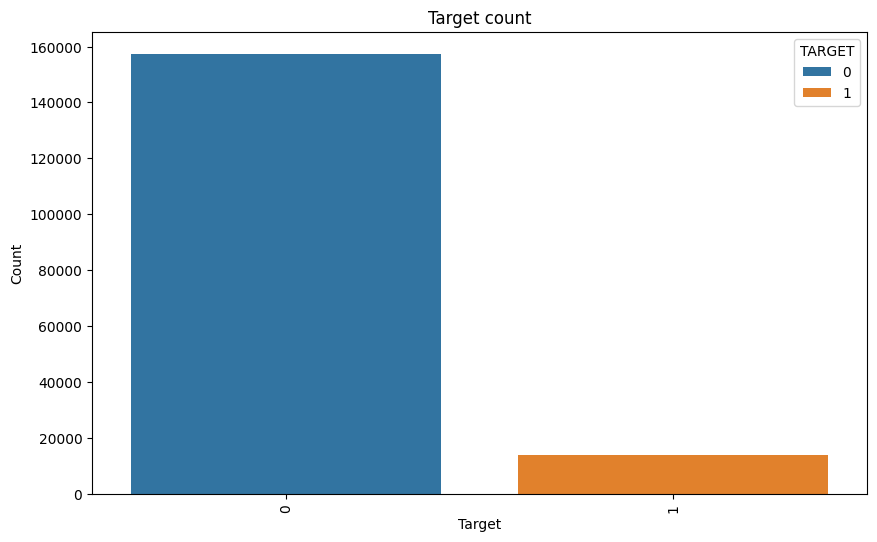

In [ ]:
#Count plot
plt.figure(figsize=(10, 6))
sns.countplot(data=train, x='TARGET',hue='TARGET')
plt.xticks(rotation=90)
plt.xlabel('Target')
plt.ylabel('Count')
plt.title('Target count')
plt.show()

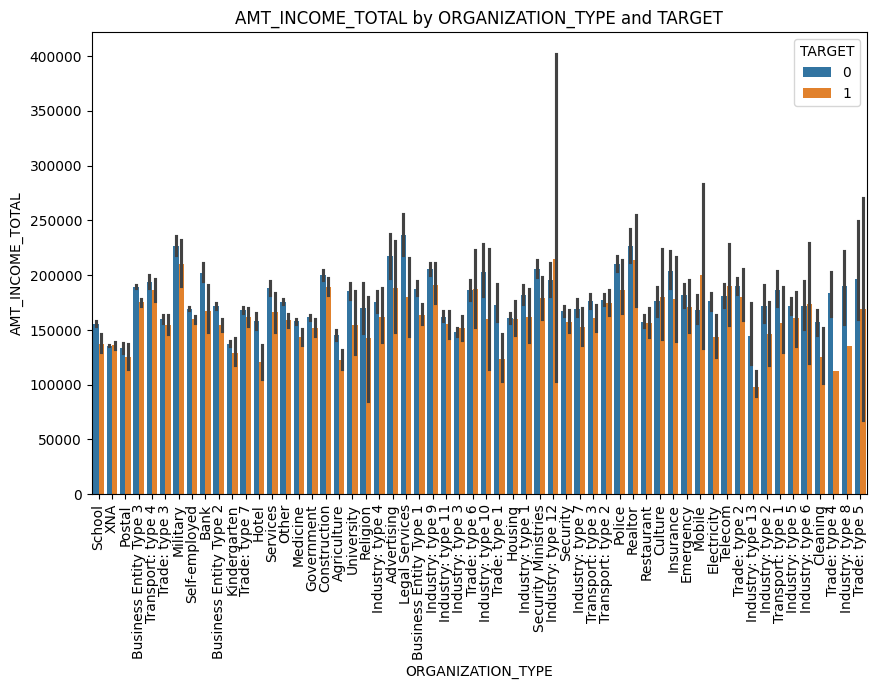

In [ ]:
#Side by side bar
plt.figure(figsize=(10, 6))
sns.barplot(data=train, x='ORGANIZATION_TYPE', y='AMT_INCOME_TOTAL', hue='TARGET')
plt.xticks(rotation=90)
plt.xlabel('ORGANIZATION_TYPE')
plt.ylabel('AMT_INCOME_TOTAL')
plt.title('AMT_INCOME_TOTAL by ORGANIZATION_TYPE and TARGET')
plt.show()


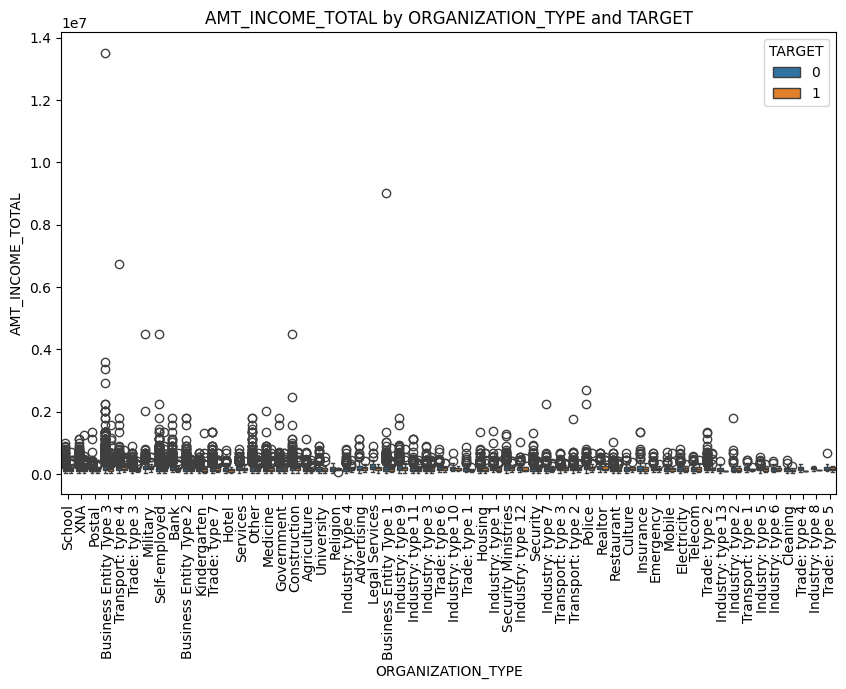

In [ ]:
#Box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=train, x='ORGANIZATION_TYPE', y='AMT_INCOME_TOTAL', hue='TARGET')
plt.xticks(rotation=90)
plt.xlabel('ORGANIZATION_TYPE')
plt.ylabel('AMT_INCOME_TOTAL')
plt.title('AMT_INCOME_TOTAL by ORGANIZATION_TYPE and TARGET')
plt.show()

### Remove outlayers and balance data for better ML predictions

```markdown
## Step 3: Outlier Removal & Categorical Encoding
To prevent extremely skewed data distributions from destabilizing our models, we define and apply an outlier removal helper function. Next, categorical columns are converted into numeric dummy variables, and standard financial ratio features are engineered to give the models more descriptive power.
```

In [ ]:
#Build function that remove out layer
def remove_outliers(df, columns, lower_quantile=0.05, upper_quantile=0.95):
  for column in df.columns:
    if column not in columns:
      continue
    elif df[column].dtype == 'object':
      continue
    else:
      Q1 = df[column].quantile(lower_quantile)
      Q3 = df[column].quantile(upper_quantile)
      IQR = Q3 - Q1
      lower_bound = Q1 - 1.5 * IQR
      upper_bound = Q3 + 1.5 * IQR
      df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
  return df

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   NAME_CONTRACT_TYPE   171202 non-null  object 
 1   AMT_INCOME_TOTAL     171202 non-null  float64
 2   EXT_SOURCE_2         171202 non-null  float64
 3   OWN_CAR_AGE          171202 non-null  float64
 4   ORGANIZATION_TYPE    171202 non-null  object 
 5   CNT_CHILDREN         171202 non-null  int64  
 6   AMT_CREDIT           171202 non-null  float64
 7   AMT_ANNUITY          171202 non-null  float64
 8   AMT_GOODS_PRICE      171202 non-null  float64
 9   NAME_INCOME_TYPE     171202 non-null  object 
 10  NAME_EDUCATION_TYPE  171202 non-null  object 
 11  NAME_FAMILY_STATUS   171202 non-null  object 
 12  NAME_HOUSING_TYPE    171202 non-null  object 
 13  DAYS_BIRTH           171202 non-null  int64  
 14  DAYS_EMPLOYED        171202 non-null  int64  
 15  DAYS_REGISTRATION

In [ ]:
train = remove_outliers(train, columns=train.columns)
print(f"New train shape after outlier removal: {train.shape}")

New train shape after outlier removal: (168869, 18)


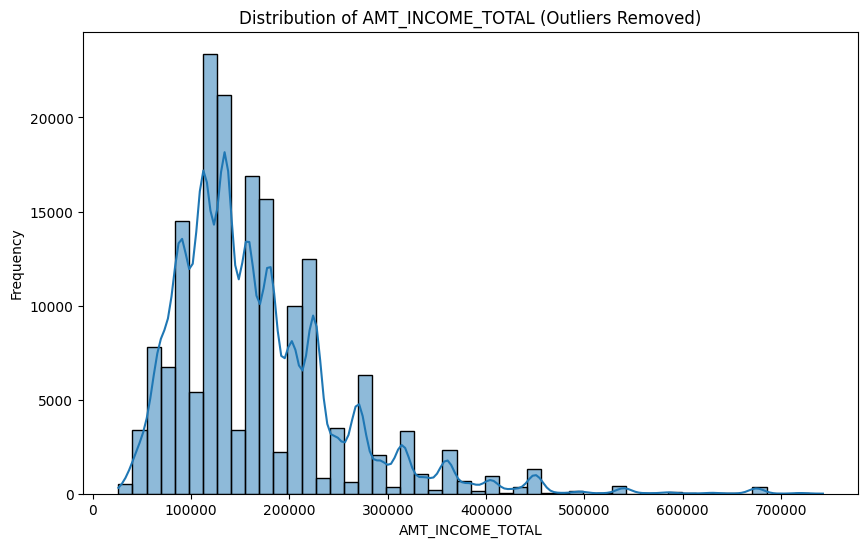

In [ ]:
# Re-plotting the distribution of AMT_INCOME_TOTAL after outlier removal
plt.figure(figsize=(10, 6))
sns.histplot(data=train, x='AMT_INCOME_TOTAL', kde=True, bins=50)
plt.xlabel('AMT_INCOME_TOTAL')
plt.ylabel('Frequency')
plt.title('Distribution of AMT_INCOME_TOTAL (Outliers Removed)')
plt.show()

In [ ]:
#Remove the outlayers of test
remove_outliers(test, columns=test.columns)
#Print new shape
print(f"New test shape after outlier removal: {test.shape}")

New test shape after outlier removal: (61500, 17)


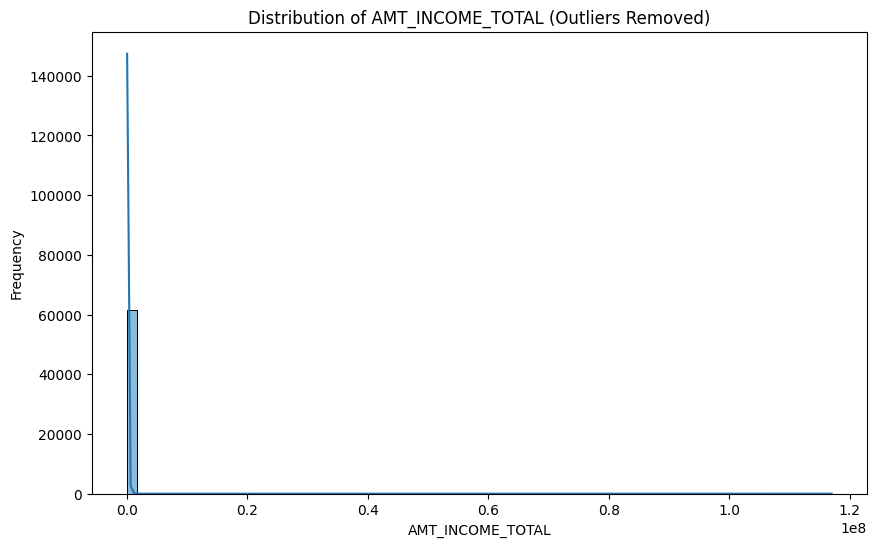

In [ ]:
#PLot test hist
plt.figure(figsize=(10, 6))
sns.histplot(data=test, x='AMT_INCOME_TOTAL', kde=True, bins=70)
plt.xlabel('AMT_INCOME_TOTAL')
plt.ylabel('Frequency')
plt.title('Distribution of AMT_INCOME_TOTAL (Outliers Removed)')
plt.show()

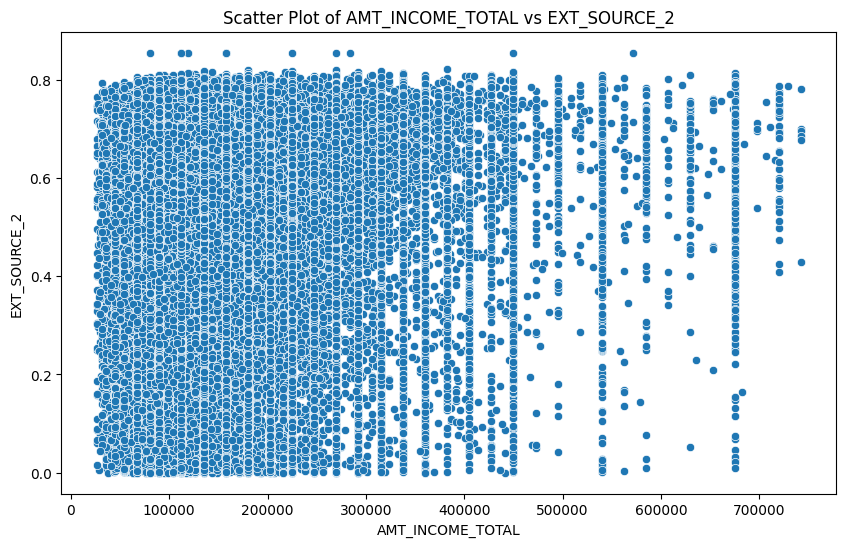

In [ ]:
#Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x='AMT_INCOME_TOTAL', y='EXT_SOURCE_2')
plt.xlabel('AMT_INCOME_TOTAL')
plt.ylabel('EXT_SOURCE_2')
plt.title('Scatter Plot of AMT_INCOME_TOTAL vs EXT_SOURCE_2')
plt.show()

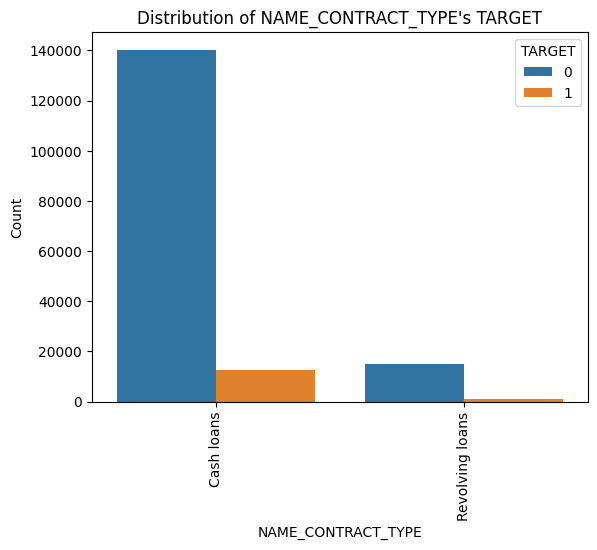

In [ ]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE", hue="TARGET")
plt.xticks(rotation=90)
plt.xlabel("NAME_CONTRACT_TYPE")
plt.ylabel("Count")
plt.title("Distribution of NAME_CONTRACT_TYPE's TARGET")
plt.show()

### Hundeling Categolical data and imbalanced data for better results

```markdown
### Why We Avoid SMOTE for Handling Class Imbalance
In this competition, we have a highly imbalanced dataset (around 8% positive targets). A common temptation is to use **SMOTE (Synthetic Minority Over-sampling Technique)** to balance our classes. However, we have intentionally **avoided** using SMOTE here to prevent **Data Leakage**:

1. **Data Leakage via Synthesis**: SMOTE creates synthetic samples based on neighboring data points. If applied to the entire dataset before splitting, the validation and test folds will contain synthetic samples whose properties were calculated directly from the training fold, artificially inflating our validation scores while performing poorly on real-world test data.
2. **Validation Integrity**: To accurately gauge true out-of-sample performance, the validation dataset must remain unmodified and represent the real population distribution. Over-sampling the validation set leads to misleading metrics.
3. **Robust Alternatives**: Instead of SMOTE, we handle imbalance natively within our algorithms using model-specific hyperparameters (e.g., `scale_pos_weight` in XGBoost and `class_weight='balanced'` in RandomForest), which penalize misclassifying the minority class without distorting the feature space.
```

In [ ]:
#Handel categolical data
train = pd.get_dummies(train, columns=['NAME_CONTRACT_TYPE'],dtype=int)
test = pd.get_dummies(test, columns=['NAME_CONTRACT_TYPE'],dtype=int)
#
train.head()

,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,TARGET,NAME_CONTRACT_TYPE_Cash loans,NAME_CONTRACT_TYPE_Revolving loans
0,112500.0,0.372591,0.0,School,0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,-9233,-878,-333.0,-522,0,1,0
1,225000.0,0.449567,0.0,XNA,0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-20148,365243,-4469.0,-3436,0,1,0
2,54000.0,0.569503,0.0,Postal,0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,-18496,-523,-3640.0,-2050,0,1,0
3,67500.0,0.105235,0.0,XNA,0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,-24177,365243,-4950.0,-3951,0,1,0
4,157500.0,0.202490,0.0,Business Entity Type 3,0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,-10685,-697,-5101.0,-3226,1,1,0


In [ ]:
#Handel categolical by sklearn
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
train['ORGANIZATION_TYPE'] = label_encoder.fit_transform(train['ORGANIZATION_TYPE'])
test['ORGANIZATION_TYPE'] = label_encoder.transform(test['ORGANIZATION_TYPE'])
train.head()

,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,CNT_CHILDREN,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,TARGET,NAME_CONTRACT_TYPE_Cash loans,NAME_CONTRACT_TYPE_Revolving loans
0,112500.0,0.372591,0.0,39,0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,-9233,-878,-333.0,-522,0,1,0
1,225000.0,0.449567,0.0,57,0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-20148,365243,-4469.0,-3436,0,1,0
2,54000.0,0.569503,0.0,35,0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,-18496,-523,-3640.0,-2050,0,1,0
3,67500.0,0.105235,0.0,57,0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,-24177,365243,-4950.0,-3951,0,1,0
4,157500.0,0.202490,0.0,5,0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,-10685,-697,-5101.0,-3226,1,1,0


In [ ]:
# Identify any remaining categorical columns with string values
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()
if 'TARGET' in categorical_cols:
    categorical_cols.remove('TARGET')

# Convert remaining categorical columns to numeric dummy variables
if categorical_cols:
    train = pd.get_dummies(train, columns=categorical_cols, dtype=int)
    # Apply the same categorical transformations to the test set to keep features aligned
    test = pd.get_dummies(test, columns=[col for col in categorical_cols if col in test.columns], dtype=int)
    # Align test set columns to match train set columns (excluding 'TARGET')
    test = test.reindex(columns=train.drop('TARGET', axis=1).columns, fill_value=0)

def add_financial_ratios(df):
    # Make a copy to avoid SettingWithCopyWarning
    df_new = df.copy()

    # 1. Debt-to-Income Ratio (Annuity vs Income)
    df_new['RATIO_ANNUITY_INCOME'] = df_new['AMT_ANNUITY'] / (df_new['AMT_INCOME_TOTAL'] + 1)

    # 2. Credit-to-Income Ratio
    df_new['RATIO_CREDIT_INCOME'] = df_new['AMT_CREDIT'] / (df_new['AMT_INCOME_TOTAL'] + 1)

    # 3. Goods-to-Credit Ratio (How much of the credit is covered by the goods price)
    df_new['RATIO_GOODS_CREDIT'] = df_new['AMT_GOODS_PRICE'] / (df_new['AMT_CREDIT'] + 1)

    # 4. Annuity-to-Credit Ratio (Interest/payment burden relative to total loan size)
    df_new['RATIO_ANNUITY_CREDIT'] = df_new['AMT_ANNUITY'] / (df_new['AMT_CREDIT'] + 1)

    return df_new

# Apply feature engineering to both train and test sets
train = add_financial_ratios(train)
test = add_financial_ratios(test)

In [ ]:
#Corr plot
corr = train.corr()
corr_target = corr['TARGET'].sort_values(ascending=False)
corr_target

,TARGET
TARGET,1.000000
DAYS_BIRTH,0.080094
NAME_INCOME_TYPE_Working,0.055452
DAYS_ID_PUBLISH,0.052494
NAME_EDUCATION_TYPE_Secondary / secondary special,0.047812
DAYS_REGISTRATION,0.042195
NAME_HOUSING_TYPE_With parents,0.031211
NAME_CONTRACT_TYPE_Cash loans,0.030063
NAME_FAMILY_STATUS_Single / not married,0.027172
NAME_HOUSING_TYPE_Rented apartment,0.023016


In [ ]:
train['TARGET'].value_counts()

,count
TARGET,
0,155233
1,13636


## Model Build for predictions

```markdown
## Step 4: Model Training, Evaluation & Ensemble Ensembling
We split our processed data into training and validation sets, scaling the continuous features. We train multiple baseline models (Logistic Regression, Random Forest, XGBoost) and optimize them using hyperparameter search. Finally, we combine them into a **Soft Voting Classifier** to maximize the ROC-AUC evaluation metric.
```

### 4.1. Data Splitting & Scaling
Before training our machine learning models, we perform two critical preprocessing steps on our engineered dataset:

1. **Train-Validation Split**: We partition our dataset into an $80\%$ training set (to train the algorithms) and a $20\%$ validation set (to evaluate their true performance on unseen data). We use a fixed `random_state` to ensure our experiments are reproducible.
2. **Feature Scaling**: Algorithms such as Logistic Regression and Support Vector Machines are highly sensitive to the scale of input features. We apply a standard Z-score scaling ($z = \frac{x - \mu}{\sigma}$) using scikit-learn's `StandardScaler` to align our continuous variables, ensuring that we only scale using statistical parameters calculated from the *training set* to avoid data leakage.

In [ ]:
#Import libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import StratifiedShuffleSplit


In [ ]:
#Build function for train and test models
def train_and_test_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    return model


In [ ]:
#Data prepration
X = train.drop('TARGET', axis=1)
y = train['TARGET']
#Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#scale the data
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)


### 4.2. Base Model Training (Logistic Regression & Random Forest)
We initialize our training process by implementing baseline estimators to establish benchmark evaluation scores:

- **Logistic Regression**: A linear model used to predict default probabilities. We evaluate its baseline, then compute its ROC-AUC performance using custom threshold optimization.
- **Random Forest**: An ensemble of decision trees. To combat class imbalance, we utilize the `class_weight='balanced'` parameter, which automatically adjusts weights inversely proportional to class frequencies in the input data.

In [ ]:
#AUC_ROC Function
def roc_Threshold_score(model, X_test, y_test):
  y_probs_eng = model.predict_proba(X_test)[:, 1]
  new_auc = roc_auc_score(y_test, y_probs_eng)
  print(f"🚀 Engineered {type(model).__name__} ROC-AUC Score: {new_auc:.4f}\n")

  # Find Optimal Threshold & Evaluate
  precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs_eng)
  f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
  best_idx = np.argmax(f1_scores)
  best_threshold = thresholds[best_idx]

  print(f"🎯 Optimal Threshold: {best_threshold:.4f}")
  y_pred_opt = (y_probs_eng >= best_threshold).astype(int)

  print("Name of model: ",type(model).__name__)
  print("\nConfusion Matrix:")
  print(confusion_matrix(y_test, y_pred_opt))
  print("\nClassification Report:")
  print(classification_report(y_test, y_pred_opt))
  print("Accuracy:", accuracy_score(y_test, y_pred_opt))
  print("F1 Score:", f1_score(y_test, y_pred_opt))
  print("Precision:", precision_score(y_test, y_pred_opt))
  print("Recall:", recall_score(y_test, y_pred_opt))
  print("Average Precision Score:", average_precision_score(y_test, y_pred_opt))
  print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_opt))

  return model


In [ ]:
#logistice Regression
log = LogisticRegression()
model1 = train_and_test_model(log, X_train_sc, y_train, X_test_sc, y_test)

Accuracy: 0.9188725054775863
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     31034
           1       0.00      0.00      0.00      2740

    accuracy                           0.92     33774
   macro avg       0.46      0.50      0.48     33774
weighted avg       0.84      0.92      0.88     33774

Confusion Matrix:
[[31034     0]
 [ 2740     0]]


In [ ]:
roc_Threshold_score(model1, X_test_sc, y_test)

🚀 Engineered LogisticRegression ROC-AUC Score: 0.7031

🎯 Optimal Threshold: 0.1234
Name of model:  LogisticRegression

Confusion Matrix:
[[26239  4795]
 [ 1636  1104]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.85      0.89     31034
           1       0.19      0.40      0.26      2740

    accuracy                           0.81     33774
   macro avg       0.56      0.62      0.57     33774
weighted avg       0.88      0.81      0.84     33774

Accuracy: 0.8095872564694736
F1 Score: 0.2555851371686538
Precision: 0.187150364468554
Recall: 0.4029197080291971
Average Precision Score: 0.12384619832553007
ROC-AUC Score: 0.6242058745082507


LogisticRegression()

In [ ]:
#RandomForest
rf = RandomForestClassifier(class_weight= 'balanced')
model2 = train_and_test_model(rf, X_train_sc, y_train, X_test_sc, y_test)

Accuracy: 0.9186652454550838
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     31034
           1       0.18      0.00      0.00      2740

    accuracy                           0.92     33774
   macro avg       0.55      0.50      0.48     33774
weighted avg       0.86      0.92      0.88     33774

Confusion Matrix:
[[31025     9]
 [ 2738     2]]


In [ ]:
roc_Threshold_score(model2, X_test_sc, y_test)

🚀 Engineered RandomForestClassifier ROC-AUC Score: 0.6873

🎯 Optimal Threshold: 0.1500
Name of model:  RandomForestClassifier

Confusion Matrix:
[[27358  3676]
 [ 1804   936]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     31034
           1       0.20      0.34      0.25      2740

    accuracy                           0.84     33774
   macro avg       0.57      0.61      0.58     33774
weighted avg       0.88      0.84      0.86     33774

Accuracy: 0.8377450109551726
F1 Score: 0.2546245919477693
Precision: 0.20294882914137033
Recall: 0.3416058394160584
Average Precision Score: 0.12274237379370691
ROC-AUC Score: 0.6115775539801178


RandomForestClassifier(class_weight='balanced')

### 4.3. Gradient Boosting with XGBoost
Gradient Boosted Decision Trees (GBDT) are generally the top-performing models on tabular datasets. We implement **XGBoost** with a large number of estimators, a conservative learning rate to prevent overfitting, and set `scale_pos_weight=11.3` to account for the imbalanced target ratio (~8% defaults vs. ~92% non-defaults).

In [ ]:
#XGBoost
xgb =XGBClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    scale_pos_weight=11.3,  # <--- Add this to penalize missing defaults
    random_state=42
)
model3 = train_and_test_model(xgb, X_train_sc, y_train, X_test_sc, y_test)

Accuracy: 0.741043406170427
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.76      0.84     31034
           1       0.17      0.57      0.26      2740

    accuracy                           0.74     33774
   macro avg       0.56      0.66      0.55     33774
weighted avg       0.89      0.74      0.80     33774

Confusion Matrix:
[[23468  7566]
 [ 1180  1560]]


In [ ]:
roc_Threshold_score(model3, X_test_sc, y_test)

🚀 Engineered XGBClassifier ROC-AUC Score: 0.7234

🎯 Optimal Threshold: 0.6106
Name of model:  XGBClassifier

Confusion Matrix:
[[27079  3955]
 [ 1649  1091]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.87      0.91     31034
           1       0.22      0.40      0.28      2740

    accuracy                           0.83     33774
   macro avg       0.58      0.64      0.59     33774
weighted avg       0.88      0.83      0.86     33774

Accuracy: 0.8340735476994138
F1 Score: 0.28024659645517597
Precision: 0.21621086008719778
Recall: 0.3981751824817518
Average Precision Score: 0.13491433825642077
ROC-AUC Score: 0.6353671555896547


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=None, num_parallel_tree=None, ...)

### 4.4. Hyperparameter Optimization & Fine-Tuning
To maximize the predictive power of our base models, we employ **Grid Search Cross-Validation (`GridSearchCV`)**. This technique searches through a user-specified parameter grid, performing 5-fold cross-validation at each combination to identify the optimal configuration based on the **ROC-AUC** metric.

In [ ]:
# Define a valid hyperparameter grid with lists of values to search
param_grid = {

    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200]
}




cv = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
cv.fit(X_train_sc, y_train)
print(f"Best Parameters: {cv.best_params_}")
print(f"Best ROC AUC Score: {cv.best_score_}")

Best Parameters: {'learning_rate': 0.05, 'n_estimators': 200}
Best ROC AUC Score: 0.7227490896939935


In [ ]:
xgb = XGBClassifier(learning_rate=0.05, max_depth=7, n_estimators=200)
model4 = train_and_test_model(xgb, X_train_sc, y_train, X_test_sc, y_test)


Accuracy: 0.9186652454550838
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     31034
           1       0.42      0.01      0.01      2740

    accuracy                           0.92     33774
   macro avg       0.67      0.50      0.49     33774
weighted avg       0.88      0.92      0.88     33774

Confusion Matrix:
[[31009    25]
 [ 2722    18]]


In [ ]:
roc_Threshold_score(model4, X_test_sc, y_test)

🚀 Engineered XGBClassifier ROC-AUC Score: 0.7262

🎯 Optimal Threshold: 0.1189
Name of model:  XGBClassifier

Confusion Matrix:
[[25691  5343]
 [ 1452  1288]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.88     31034
           1       0.19      0.47      0.27      2740

    accuracy                           0.80     33774
   macro avg       0.57      0.65      0.58     33774
weighted avg       0.89      0.80      0.83     33774

Accuracy: 0.7988097352993427
F1 Score: 0.27489061999786574
Precision: 0.1942391796109184
Recall: 0.47007299270072994
Average Precision Score: 0.13429824284138964
ROC-AUC Score: 0.6489534906147202


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
rf2 = RandomForestClassifier(max_depth=10, n_estimators=200,min_samples_leaf=1,max_leaf_nodes=5)
model5 = train_and_test_model(rf2, X_train_sc, y_train, X_test_sc, y_test)

Accuracy: 0.9188725054775863
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     31034
           1       0.00      0.00      0.00      2740

    accuracy                           0.92     33774
   macro avg       0.46      0.50      0.48     33774
weighted avg       0.84      0.92      0.88     33774

Confusion Matrix:
[[31034     0]
 [ 2740     0]]


In [ ]:
roc_Threshold_score(model5, X_test_sc, y_test)

🚀 Engineered RandomForestClassifier ROC-AUC Score: 0.6926

🎯 Optimal Threshold: 0.1002
Name of model:  RandomForestClassifier

Confusion Matrix:
[[26976  4058]
 [ 1760   980]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.87      0.90     31034
           1       0.19      0.36      0.25      2740

    accuracy                           0.83     33774
   macro avg       0.57      0.61      0.58     33774
weighted avg       0.88      0.83      0.85     33774

Accuracy: 0.8277373127257653
F1 Score: 0.2519928002057084
Precision: 0.1945216355696705
Recall: 0.35766423357664234
Average Precision Score: 0.12168452307216249
ROC-AUC Score: 0.6134522108786736


RandomForestClassifier(max_depth=10, max_leaf_nodes=5, n_estimators=200)

In [ ]:
#logestice regression GradiantSearch
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}
cv3 = GridSearchCV(estimator=log, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
cv3.fit(X_train_sc, y_train)
print(f"Best Log Parameters: {cv3.best_params_}")
print(f"Best Log ROC AUC Score: {cv3.best_score_}")

Best Log Parameters: {'C': 100, 'penalty': 'l2'}
Best Log ROC AUC Score: 0.6957265154549033


In [ ]:
#Build new model
log2 = LogisticRegression(C=100, penalty='l2')
model6 = train_and_test_model(log2, X_train_sc, y_train, X_test_sc, y_test)


Accuracy: 0.9188725054775863
Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     31034
           1       0.00      0.00      0.00      2740

    accuracy                           0.92     33774
   macro avg       0.46      0.50      0.48     33774
weighted avg       0.84      0.92      0.88     33774

Confusion Matrix:
[[31034     0]
 [ 2740     0]]


In [ ]:
roc_Threshold_score(model6, X_test_sc, y_test)

🚀 Engineered LogisticRegression ROC-AUC Score: 0.7047

🎯 Optimal Threshold: 0.1211
Name of model:  LogisticRegression

Confusion Matrix:
[[25992  5042]
 [ 1596  1144]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.84      0.89     31034
           1       0.18      0.42      0.26      2740

    accuracy                           0.80     33774
   macro avg       0.56      0.63      0.57     33774
weighted avg       0.88      0.80      0.84     33774

Accuracy: 0.8034582815183277
F1 Score: 0.25632982298902085
Precision: 0.18493372130617525
Recall: 0.41751824817518246
Average Precision Score: 0.12446848847884553
ROC-AUC Score: 0.6275256382333668


LogisticRegression(C=100)

### 4.5. Evaluation & Performance Diagnostic Visualizations
Evaluating a model requires looking beyond raw accuracy, especially on imbalanced datasets where a naive model predicting "No Default" for everything would achieve ~92% accuracy. We plot **Confusion Matrices** and **Receiver Operating Characteristic (ROC) Curves** to inspect our models' True Positive vs. False Positive trade-offs.

In [ ]:
#Make function for plot confusion matrix
def plot_confusion_matrix(model, X_test, y_test):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix of Model {type(model).__name__}')
    plt.show()


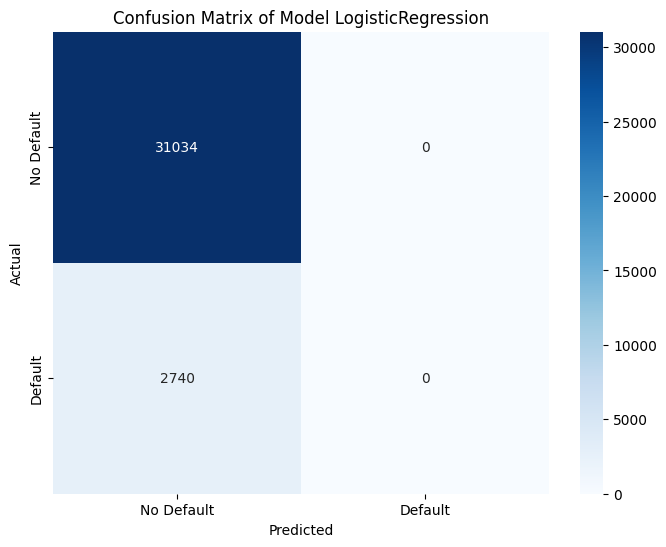

In [ ]:
plot_confusion_matrix(model=model1, X_test=X_test_sc, y_test=y_test)

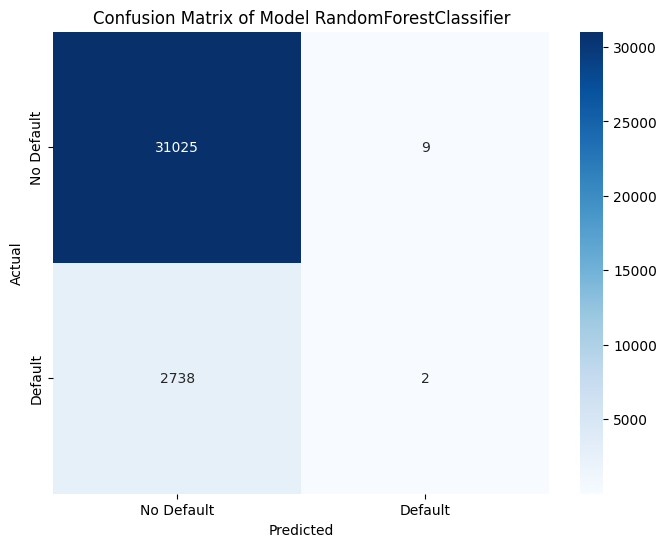

In [ ]:
plot_confusion_matrix(model=model2, X_test=X_test_sc, y_test=y_test)

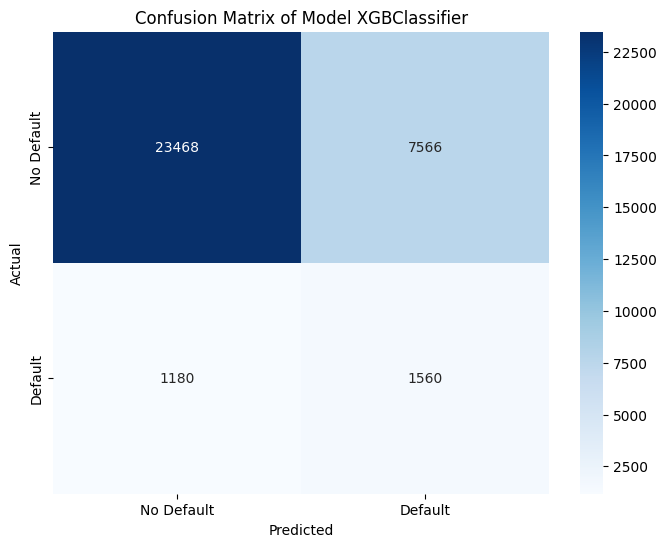

In [ ]:
plot_confusion_matrix(model=model3, X_test=X_test_sc, y_test=y_test)

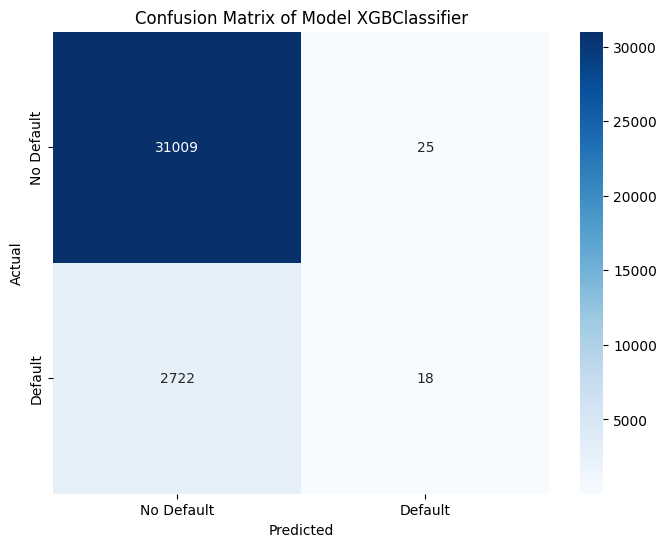

In [ ]:
plot_confusion_matrix(model=model4, X_test=X_test_sc, y_test=y_test)

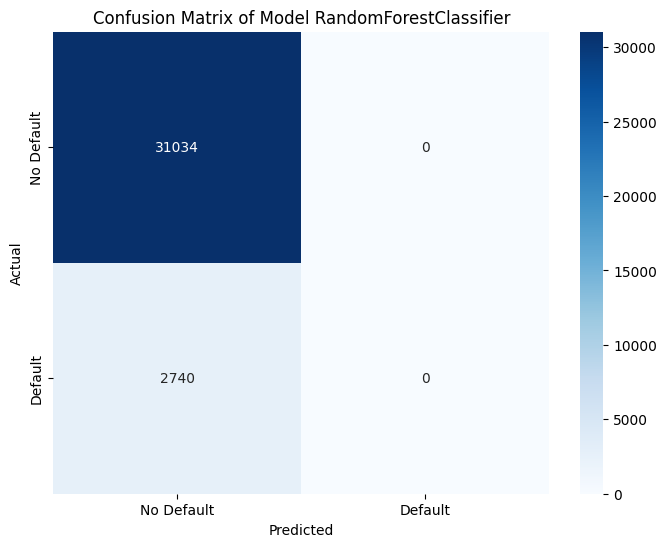

In [ ]:
plot_confusion_matrix(model=model5, X_test=X_test_sc, y_test=y_test)

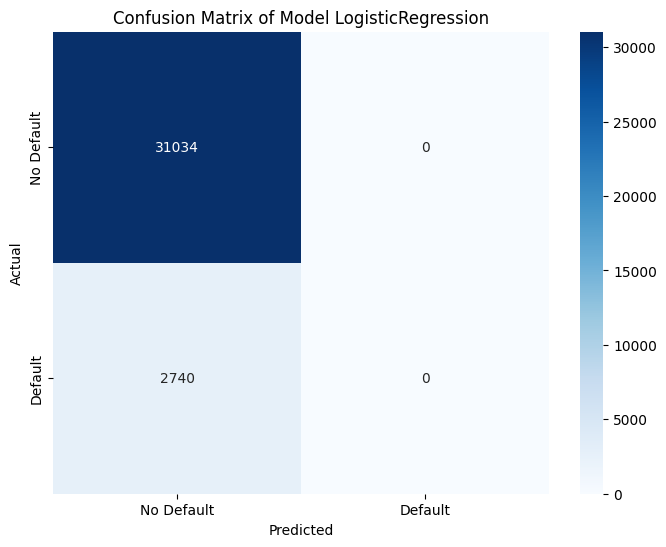

In [ ]:
plot_confusion_matrix(model=model6, X_test=X_test_sc, y_test=y_test)

In [ ]:
#AUC Plot function
def plot_roc_curve(model, X_test, y_test):
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)
    mean_fpr = np.linspace(0, 1, 100)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1],linestyle = '--', color='navy', lw=2, label='Random Classifier')
    plt.plot([0,0,1],[0,1,1],linestyle=':',color='black')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve of Model {type(model).__name__}')
    plt.legend(loc="lower right")
    plt.show()

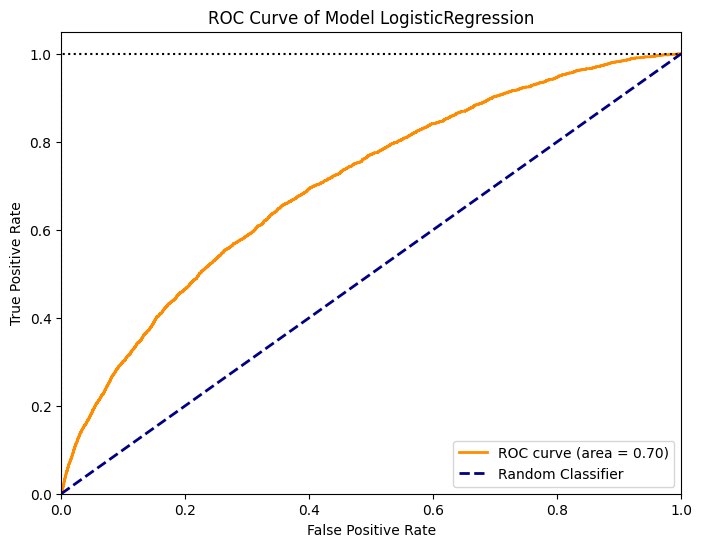

In [ ]:
plot_roc_curve(model=model1, X_test=X_test_sc, y_test=y_test)

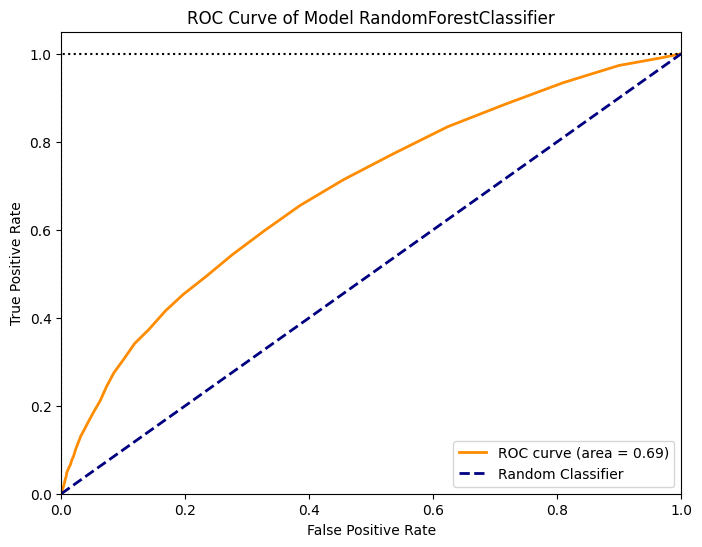

In [ ]:
plot_roc_curve(model=model2, X_test=X_test_sc, y_test=y_test)

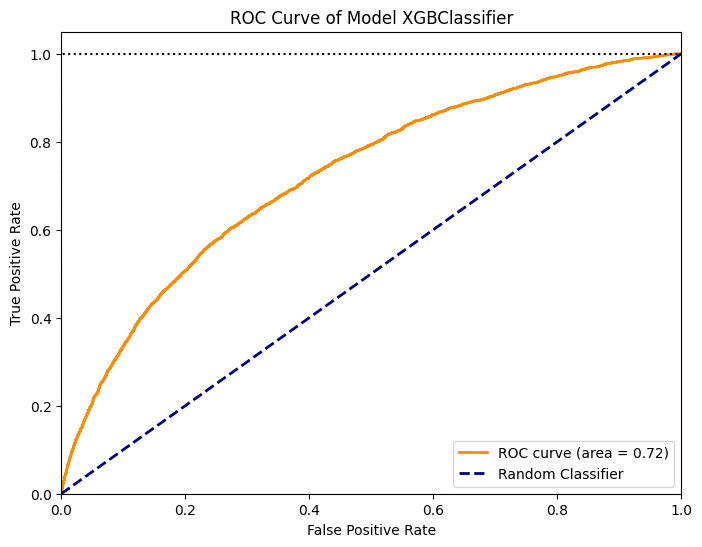

In [ ]:
plot_roc_curve(model=model3, X_test=X_test_sc, y_test=y_test)

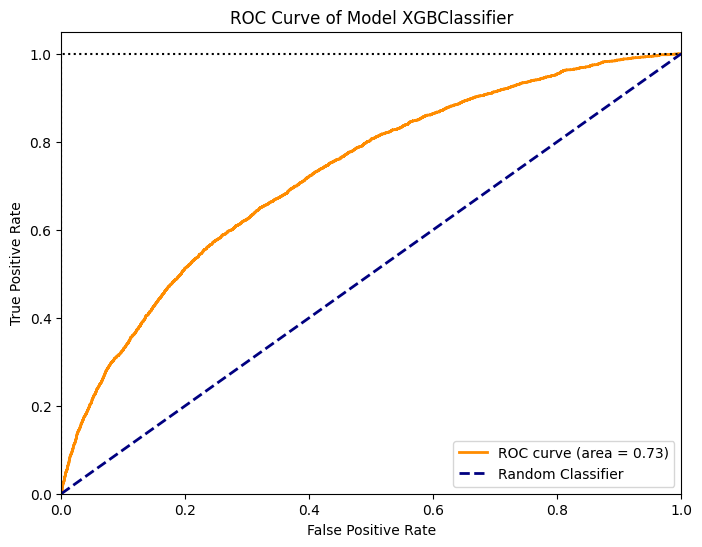

In [ ]:
plot_roc_curve(model=model4, X_test=X_test_sc, y_test=y_test)

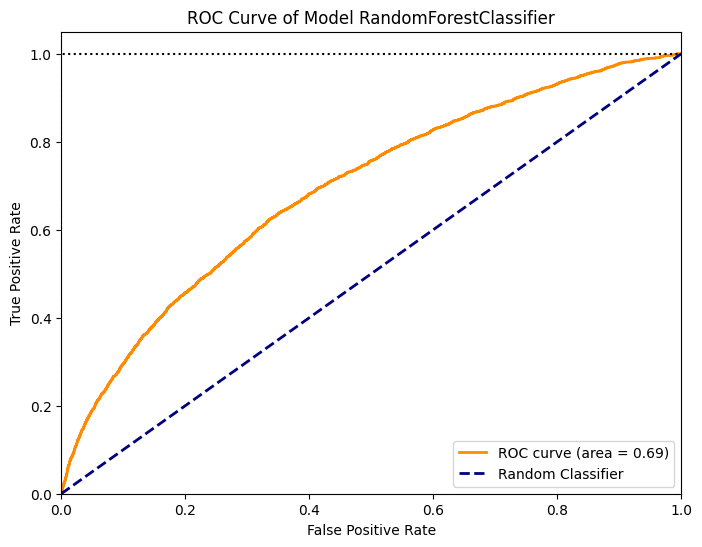

In [ ]:
plot_roc_curve(model=model5, X_test=X_test_sc, y_test=y_test)

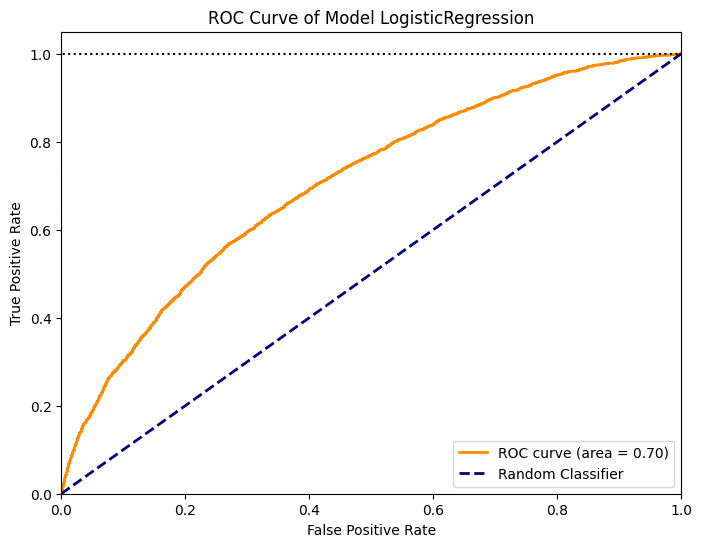

In [ ]:
plot_roc_curve(model=model6, X_test=X_test_sc, y_test=y_test)

In [ ]:
#Models data collection
def data_models_collection(model, X_train, y_train, X_test, y_test):
    results = {}
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results['Accuracy'] = accuracy
    results['ROC-AUC Score'] = roc_auc_score(y_test, y_pred)
    results['Precision'] = precision_score(y_test, y_pred)
    results['Recall'] = recall_score(y_test, y_pred)
    results['F1 Score'] = f1_score(y_test, y_pred)
    results['Average Precision Score'] = average_precision_score(y_test, y_pred)
    return results

In [ ]:
#Kfold function
def kfold_cross_validation(model, X, y, n_splits=5):
    kfold = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = []
    for train_index, test_index in kfold.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        score = roc_auc_score(y_test, y_pred)
        scores.append(score)
    return scores


In [73]:
kfold_cross_validation(model=model1, X=X, y=y, n_splits=5)
kfold_cross_validation(model=model2, X=X, y=y, n_splits=5)
kfold_cross_validation(model=model3, X=X, y=y, n_splits=5)
kfold_cross_validation(model=model4, X=X, y=y, n_splits=5)
kfold_cross_validation(model=model5, X=X, y=y, n_splits=5)
kfold_cross_validation(model=model6, X=X, y=y, n_splits=5)


[np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5)]

### 4.6. Advanced Model Ensembling (Voting Classifiers)
Ensembling leverages the "wisdom of the crowd" by combining predictions from multiple diverse models to reduce variance and improve generalization. We implement two ensemble approaches:

1. **Majority Vote Classifier**: A custom hard/soft voting meta-estimator that wraps scikit-learn pipelines.
2. **Soft Voting Classifier**: Combines predictions by averaging the predicted probabilities of class membership from our best-performing estimators (XGBoost, Logistic Regression, and Random Forest), outputting robust probability estimates.

In [74]:
#Ensamble models class
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import _fit_transform_one, _transform_one
from sklearn.utils.validation import check_is_fitted
from sklearn.pipeline import _name_estimators
import numpy as np

class MajorityVoteClassifier(BaseEstimator, ClassifierMixin):
    """ A majority vote ensemble classifier

    Parameters
    ----------
    classifiers : array-like, shape = [n_classifiers]
    Different classifiers for the ensemble

    vote : str, {'classlabel', 'probability'}
    Default: 'classlabel'
    If 'classlabel' the prediction is based on
    the argmax of class labels. Else if
    'probability', the argmax of the sum of
    probabilities is used to predict the class label
    (recommended for calibrated classifiers).

    weights : array-like, shape = [n_classifiers]
    Optional, default: None
    If a list of 'int' or 'float' values are
    provided, the classifiers are weighted by
    importance; Uses uniform weights if 'weights=None'.

    """
    def __init__(self, classifiers, vote='classlabel', weights=None):
        self.classifiers = classifiers
        self.named_classifiers = {key: value for key, value in _name_estimators(classifiers)}
        self.vote = vote
        self.weights = weights

    def fit(self, X, y):
        """ Fit classifiers.

        Parameters
        ----------
        X : {array-like, sparse matrix},
        shape = [n_examples, n_features]
        Matrix of training examples.

        y : array-like, shape = [n_examples]
        Vector of target class labels.

        Returns
        -------
        self : object

        """
        if self.vote not in ('probability', 'classlabel'):
            raise ValueError("vote must be 'probability' or 'classlabel'; got (vote=%r)" % self.vote)
        if self.weights and len(self.weights) != len(self.classifiers):
            raise ValueError("Number of classifiers and weights must be equal; got %d weights, %d classifiers" % (len(self.weights), len(self.classifiers)))

        # Use LabelEncoder to ensure class labels start
        # with 0, which is important for np.argmax
        # call in self.predict
        self.lablenc_ = LabelEncoder()
        self.lablenc_.fit(y)
        self.classes_ = self.lablenc_.classes_
        self.classifiers_ = []
        for clf in self.classifiers:
            fitted_clf = clone(clf).fit(X, self.lablenc_.transform(y))
            self.classifiers_.append(fitted_clf)
        return self

    def predict(self, X):
        """ Predict class labels for X.

        Parameters
        ----------
        X : {array-like, sparse matrix},
        Shape = [n_examples, n_features]
        Matrix of training examples.

        Returns
        ----------
        maj_vote : array-like, shape = [n_examples]
        Predicted class labels.

        """
        if self.vote == 'probability':
            maj_vote = np.argmax(self.predict_proba(X), axis=1)
        else: # 'classlabel' vote
            # Collect results from clf.predict calls
            predictions = np.asarray([clf.predict(X) for clf in self.classifiers_]).T

            maj_vote = np.apply_along_axis(
                lambda x: np.argmax(np.bincount(x, weights=self.weights)),
                axis=1,
                arr=predictions
            )
        maj_vote = self.lablenc_.inverse_transform(maj_vote)
        return maj_vote

    def predict_proba(self, X):
        """ Predict class probabilities for X.

        Parameters
        ----------
        X : {array-like, sparse matrix},
        shape = [n_examples, n_features]
        Training vectors, where
        n_examples is the number of examples and
        n_features is the number of features.

        Returns
        ----------
        avg_proba : array-like,
        shape = [n_examples, n_classes]
        Weighted average probability for
        each class per example.

        """
        probas = np.asarray([clf.predict_proba(X) for clf in self.classifiers_])
        avg_proba = np.average(probas, axis=0, weights=self.weights)
        return avg_proba

    def get_params(self, deep=True):
        """ Get classifier parameter names for GridSearch"""
        if not deep:
            return super(MajorityVoteClassifier, self).get_params(deep=False)
        else:
            out = self.named_classifiers.copy()
            for name, step in self.named_classifiers.items():
                for key, value in step.get_params(deep=True).items():
                    out['%s__%s' % (name, key)] = value
            return out

In [75]:
#Pipline models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

pip1 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model1)
])

pip2 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model2)])
pip3 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model3)])
pip4 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model4)])
pip5 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model5)])
pip6 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', model6)])

ensambel_models = [pip1, pip2, pip3, pip4, pip5, pip6]
Ensamble_models = MajorityVoteClassifier(classifiers=ensambel_models)

In [76]:
Ensamble_models.fit(X_train_sc, y_train)

MajorityVoteClassifier(classifiers=[Pipeline(steps=[('scaler',
                                                     StandardScaler()),
                                                    ('clf',
                                                     LogisticRegression())]),
                                    Pipeline(steps=[('scaler',
                                                     StandardScaler()),
                                                    ('clf',
                                                     RandomForestClassifier(class_weight='balanced'))]),
                                    Pipeline(steps=[('scaler',
                                                     StandardScaler()),
                                                    ('clf',
                                                     XGBClassifier(base_score=None,
                                                                   booster=None,
                                                                   callbacks=None,
                                                                   colsample_bylevel=None,
                                                                   colsa...
                                                                   max_leaves=None,
                                                                   min_child_weight=None,
                                                                   missing=nan,
                                                                   monotone_constraints=None,
                                                                   multi_strategy=None,
                                                                   n_estimators=200,
                                                                   n_jobs=None,
                                                                   num_parallel_tree=None, ...))]),
                                    Pipeline(steps=[('scaler',
                                                     StandardScaler()),
                                                    ('clf',
                                                     RandomForestClassifier(max_depth=10,
                                                                            max_leaf_nodes=5,
                                                                            n_estimators=200))]),
                                    Pipeline(steps=[('scaler',
                                                     StandardScaler()),
                                                    ('clf',
                                                     LogisticRegression(C=100))])])

In [ ]:
Ensamble_models.predict(X_test_sc)

In [ ]:
#Find out score
roc_Threshold_score(Ensamble_models, X_test_sc, y_test)

In [ ]:
#Soft voting classifier
from sklearn.ensemble import VotingClassifier

estemator = [
    ('xgb', model3),
    ('log', model1),
    ('rf', model2),
    ('lgb', model4)
]

voting_clf = VotingClassifier(
    estimators=estemator,
    voting='soft')
voting_clf.fit(X_train_sc, y_train)
y_pred = voting_clf.predict(X_test_sc)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred)}")


In [80]:
roc_Threshold_score(voting_clf, X_test_sc, y_test)

🚀 Engineered VotingClassifier ROC-AUC Score: 0.7280

🎯 Optimal Threshold: 0.2581
Name of model:  VotingClassifier

Confusion Matrix:
[[27484  3550]
 [ 1703  1037]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91     31034
           1       0.23      0.38      0.28      2740

    accuracy                           0.84     33774
   macro avg       0.58      0.63      0.60     33774
weighted avg       0.88      0.84      0.86     33774

Accuracy: 0.8444661573991828
F1 Score: 0.28306264501160094
Precision: 0.22607368650534118
Recall: 0.3784671532846715
Average Precision Score: 0.13598486718164574
ROC-AUC Score: 0.6320382424926935


VotingClassifier(estimators=[('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=True,
                                            eval_metric=None,
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constrai...
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.05, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=7,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=200, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 voting='soft')

In [ ]:
#Collect models results
results = {}
results['Logistic Regression'] = data_models_collection(model=model1, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['Random Forest'] = data_models_collection(model=model2, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['XGBoost'] = data_models_collection(model=model3, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['XGBoost2(tuned)'] = data_models_collection(model=model4, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['Random Forest2(tuned)'] = data_models_collection(model=model5, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['Logistic Regression2(tuned)'] = data_models_collection(model=model6, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['Majoret Vote'] = data_models_collection(model=Ensamble_models, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)
results['Soft Voting'] = data_models_collection(model=voting_clf, X_train=X_train_sc, y_train=y_train, X_test=X_test_sc, y_test=y_test)


In [ ]:
results = pd.DataFrame(results).T
results.columns = ['Accuracy', 'ROC-AUC Score', 'Precision', 'Recall', 'F1 Score', 'Average Precision Score']
results

In [ ]:
sample_sub.head()

### Predict on Test Data and Generate Submission File

In [ ]:
def generate_submission(model, test_df, original_test, sample_sub_df, scaler=None):
    # 1. Scale test features to match the training pipeline
    if scaler is not None:
        test_sc = scaler.transform(test_df)
    else:
        test_sc = test_df

    # 2. Predict default probability (class 1)
    test_probs = model.predict_proba(test_sc)[:, 1]

    # 3. Create submission DataFrame
    submission = sample_sub_df.copy()
    submission['TARGET'] = test_probs

    # Ensure the ID column matches
    submission['SK_ID_CURR'] = original_test['SK_ID_CURR'].values

    # 4. Save to CSV file
    output_path = 'input/submission.csv'
    submission.to_csv(output_path, index=False)
    print(f"Submission file successfully saved to: {output_path}")

    return submission

# Generate predictions using our soft voting classifier (voting_clf)
submission_df = generate_submission(
    model=voting_clf,
    test_df=test,
    original_test=df_test,
    sample_sub_df=sample_sub,
    scaler=scaler
)

# Preview the submission
display(submission_df.head())
